# Multilayer local score with an entropy-barrier window: does it raise Inception Score?

**Run:** 2026-10-21, commit `2c2dc90` (+ `--scale_multiplier` control, commit noted in the
config cell below). Seed 0, 500 samples per configuration, Inception Score over 5 splits.

### The model

`MultilayerLocalScoreModule` adds a second layer on top of the existing `LocalScoreModule`:

1. Layer 1 is plain LS: a per-pixel Gaussian posterior over training patches in a $k_1\times k_1$
   window gives $\hat{x}_1$.
2. Layer 2 sees **only** $\hat{x}_1$. Using a larger window $k_2$ it forms a posterior
   $w_n(p)$ over all training images $n$, and adds the expected error of the layer-1 estimate,
   $\;\delta(p) = \sum_n w_n(p)\,\bigl(x_n(p) - \hat{x}_1(p)\bigr)$.
3. The full estimate is $\hat{x} = \hat{x}_1 + \delta$, converted to a score by the usual
   convention $s = (a_t\hat{x} - x)/b_t^2$.

`EntropyBarrierMLSModule` chooses $k_2$ at every denoising step: the **largest** candidate window
whose layer-2 posterior entropy is still $\ge$ `barrier` nats. Entropy falls as the window grows
(a big window matches one training image and the posterior collapses), so the barrier is a floor on
how much of the training set the layer is still averaging over.

> **Wording check for hshunt.** The request was "the large length scale that stays *below* some
> posterior entropy barrier". Entropy *decreases* with $k$ here, so "largest $k$ below the barrier"
> is degenerate — it always selects the biggest candidate. This implements the non-degenerate
> reading: the largest scale that has *not yet* collapsed onto a single training image. If you
> meant the other one, it is a one-line flip of the comparison.

### What this notebook has to settle

IS can be bought outright with memorization: real CIFAR-10 images score 8.75 on this eval, so any
model that copies the training set wins. Every run therefore also reports the median RMS distance
from each sample to its nearest training image (same class when conditional), and the fraction of
samples within 0.05 RMS of one. **The claim to test is not "higher IS" but "higher IS at matched
distance to the training set"**, against plain LS with its windows scaled up as the control.

## Load every run

In [1]:
import json, subprocess, sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
import torch

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
RES = ROOT / 'results' / 'mls_inception'

RUNS = []
for f in sorted(RES.glob('2026-10-21*/*/metrics.json')):
    m = json.load(open(f))
    m['run'], m['dir'] = f.parent.name, f.parent
    m['mult'] = m.get('scale_multiplier') or 1.0
    m['seed'] = 1 if f.parent.name.endswith('seed1') else 0
    m['config'] = ('real images' if m['method'] == 'real' else
                   ('LS' if m['mult'] == 1.0 else f"LS (windows x{m['mult']:g})") if m['method'] == 'LS' else
                   f"EBMLS barrier {m['barrier']:g}")
    RUNS.append(m)


def sel(dataset=None, method=None, mult=None, seed=0, sort=None):
    out = [r for r in RUNS
           if (dataset is None or r['dataset'] == dataset)
           and (method is None or r['method'] == method)
           and (mult is None or r['mult'] == mult)
           and (seed is None or r['seed'] == seed)]
    return sorted(out, key=lambda r: r[sort] if r[sort] is not None else 0) if sort else out


DSETS = [d for d in ['cifar10', 'mnist', 'celeba'] if sel(dataset=d)]
print(f'{len(RUNS)} runs over {DSETS}; commit '
      + subprocess.run(['git', '-C', str(ROOT), 'rev-parse', '--short', 'HEAD'],
                       capture_output=True, text=True).stdout.strip())

24 runs over ['cifar10', 'mnist', 'celeba']; commit 


## Metrics

`IS` is the Inception Score (higher = better, 5 splits; the $\pm$ is the split spread, not a seed
spread — with 500 samples it understates run-to-run variation). `NN-RMS` is the median distance to
the nearest training image in normalized pixel units (**higher = less like the training set**);
`copy` is the fraction of samples within 0.05 RMS of a training image.

In [2]:
ORDER = {'real': 0, 'LS': 1, 'MLS': 2, 'EBMLS': 3}
hdr = f"{'dataset':8s} {'configuration':22s} {'seed':>4s} {'IS':>14s} {'NN-RMS':>7s} {'copy':>6s} {'gen_s':>6s}"
print(hdr + '\n' + '-' * len(hdr))
for r in sorted(RUNS, key=lambda r: (r['dataset'], ORDER[r['method']], r['mult'], r['barrier'] or 0, r['seed'])):
    nn = '   —  ' if r['nn_rms_median'] is None else f"{r['nn_rms_median']:7.3f}"
    cp = '  —  ' if r['copy_fraction'] is None else f"{r['copy_fraction']:6.3f}"
    print(f"{r['dataset']:8s} {r['config']:22s} {r['seed']:4d} "
          f"{r['IS_mean']:7.3f} ± {r['IS_std']:.3f} {nn} {cp} {r['gen_seconds']:6.0f}")

dataset  configuration          seed             IS  NN-RMS   copy  gen_s
-------------------------------------------------------------------------
celeba   real images               0   3.307 ± 0.119    —     —        0
celeba   LS                        0   2.393 ± 0.043   0.357  0.000    254
celeba   EBMLS barrier 1           0   1.644 ± 0.031   0.172  0.000   2477
cifar10  real images               0   8.753 ± 0.465    —     —        0
cifar10  LS                        0   2.777 ± 0.157   0.342  0.000     33
cifar10  LS                        1   2.857 ± 0.061   0.343  0.000     32
cifar10  LS (windows x1.5)         0   4.610 ± 0.215   0.299  0.000     63
cifar10  LS (windows x2)           0   6.286 ± 0.563   0.270  0.000     97
cifar10  LS (windows x2)           1   6.073 ± 0.590   0.274  0.000     98
cifar10  LS (windows x2.25)        0   6.803 ± 0.365   0.240  0.028    359
cifar10  LS (windows x2.5)         0   7.780 ± 0.360   0.191  0.146    433
cifar10  LS (windows x3)       

## Figure 1 — IS against the barrier

The LS baseline (dashed) is the previous best on this eval; the real-image ceiling (dotted) is what
pure memorization would score.

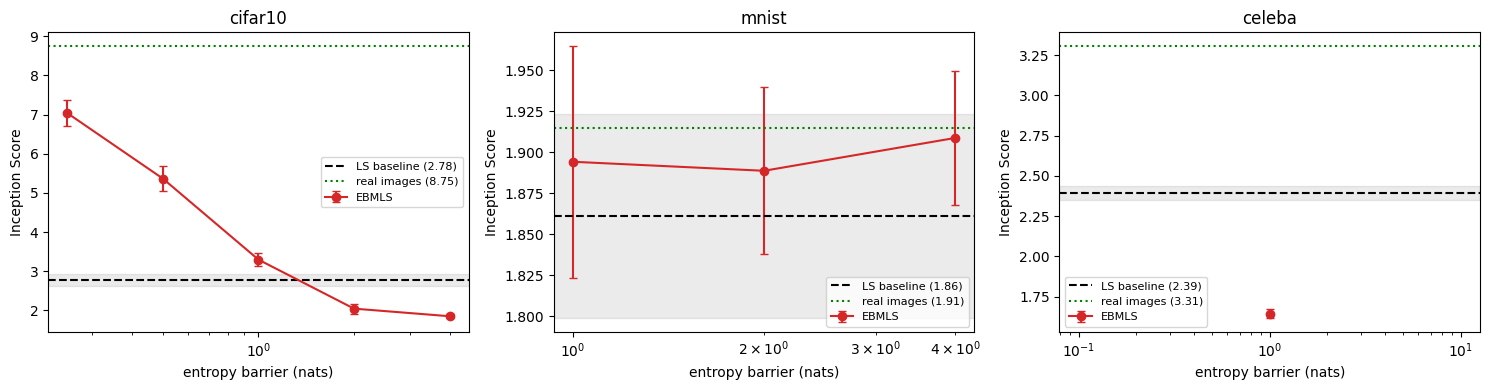

In [3]:
fig, axes = plt.subplots(1, len(DSETS), figsize=(5 * len(DSETS), 4), squeeze=False)
for ax, d in zip(axes[0], DSETS):
    eb = sel(dataset=d, method='EBMLS', sort='barrier')
    if eb:
        ax.errorbar([r['barrier'] for r in eb], [r['IS_mean'] for r in eb],
                    yerr=[r['IS_std'] for r in eb], marker='o', capsize=3, c='C3', label='EBMLS')
    ls = sel(dataset=d, method='LS', mult=1.0)
    if ls:
        ax.axhline(ls[0]['IS_mean'], ls='--', c='k', label=f"LS baseline ({ls[0]['IS_mean']:.2f})")
        ax.axhspan(*(ls[0]['IS_mean'] + np.array([-1, 1]) * ls[0]['IS_std']), color='k', alpha=.08)
    rl = sel(dataset=d, method='real')
    if rl:
        ax.axhline(rl[0]['IS_mean'], ls=':', c='g', label=f"real images ({rl[0]['IS_mean']:.2f})")
    ax.set_xscale('log'); ax.set_xlabel('entropy barrier (nats)'); ax.set_ylabel('Inception Score')
    ax.set_title(d); ax.legend(fontsize=8)
fig.tight_layout()

## Figure 2 — the figure that decides it: IS against distance to the training set

Every point is one configuration. Right = samples are far from the training set (not copying);
up = higher IS. A method only beats the baseline if it sits **above the single-layer LS curve at the
same x**. The LS points at several window multipliers trace that single-layer frontier.

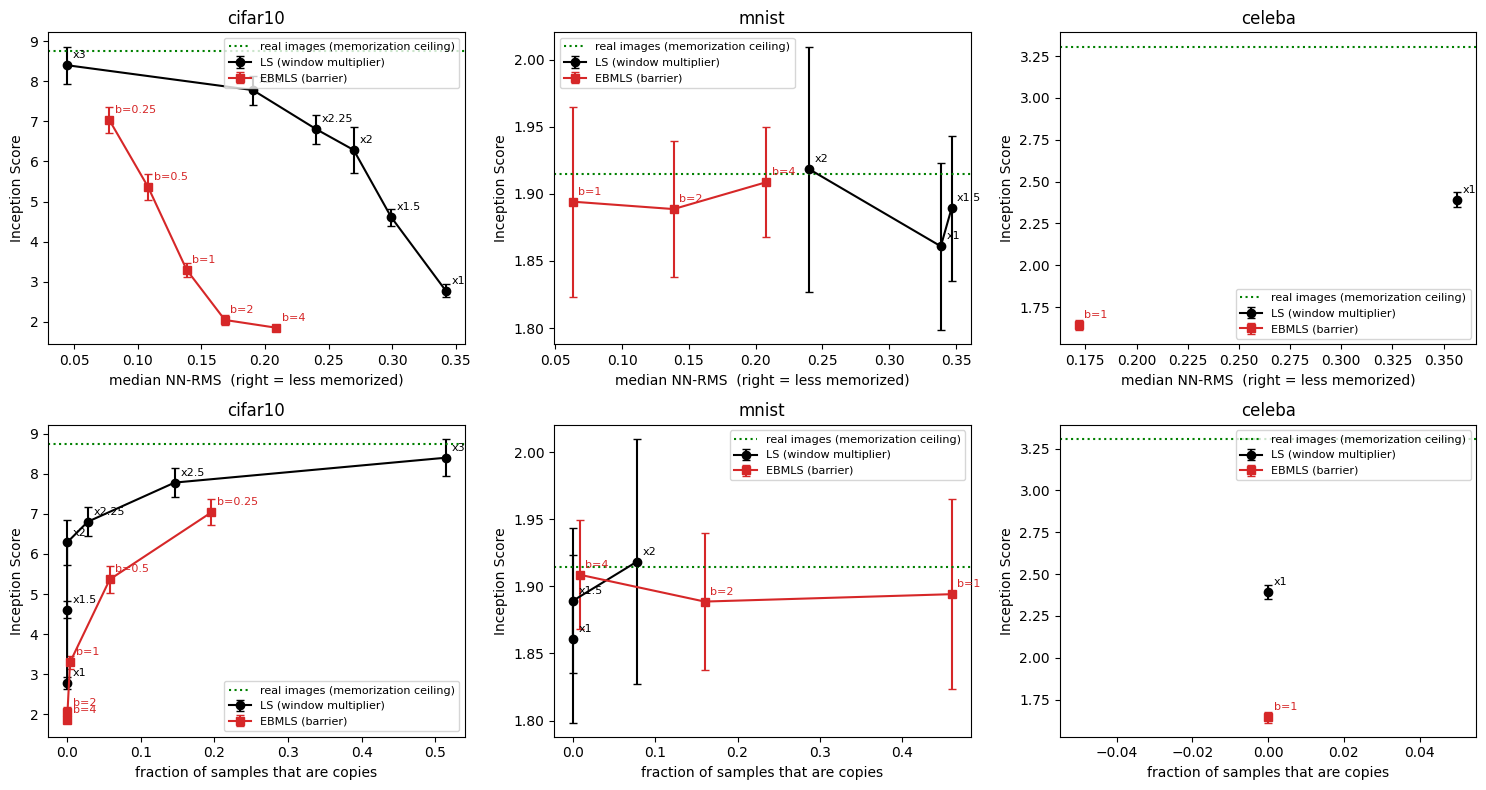

In [4]:
fig, axes = plt.subplots(2, len(DSETS), figsize=(5 * len(DSETS), 8), squeeze=False)
for col, d in enumerate(DSETS):
    for row, (xkey, xlab) in enumerate([('nn_rms_median', 'median NN-RMS  (right = less memorized)'),
                                        ('copy_fraction', 'fraction of samples that are copies')]):
        ax = axes[row][col]
        for meth, c, mk, lab in [('LS', 'k', 'o-', 'LS (window multiplier)'),
                                 ('EBMLS', 'C3', 's-', 'EBMLS (barrier)')]:
            s = sorted(sel(dataset=d, method=meth), key=lambda r: r[xkey])
            if not s:
                continue
            ax.errorbar([r[xkey] for r in s], [r['IS_mean'] for r in s],
                        yerr=[r['IS_std'] for r in s], fmt=mk, c=c, capsize=3, label=lab)
            for r in s:
                tag = f"x{r['mult']:g}" if meth == 'LS' else f"b={r['barrier']:g}"
                ax.annotate(tag, (r[xkey], r['IS_mean']), fontsize=8, color=c,
                            xytext=(4, 5), textcoords='offset points')
        rl = sel(dataset=d, method='real')
        if rl:
            ax.axhline(rl[0]['IS_mean'], ls=':', c='g', label='real images (memorization ceiling)')
        ax.set_xlabel(xlab); ax.set_ylabel('Inception Score'); ax.set_title(d); ax.legend(fontsize=8)
fig.tight_layout()

## Figure 3 — the window schedule the barrier produces

`layer2_k_by_t` is the average layer-2 window the barrier selected at each denoising step
($k=0$ means no candidate passed, so the step is plain LS). Nothing imposes a schedule; it falls
out of the entropy constraint.

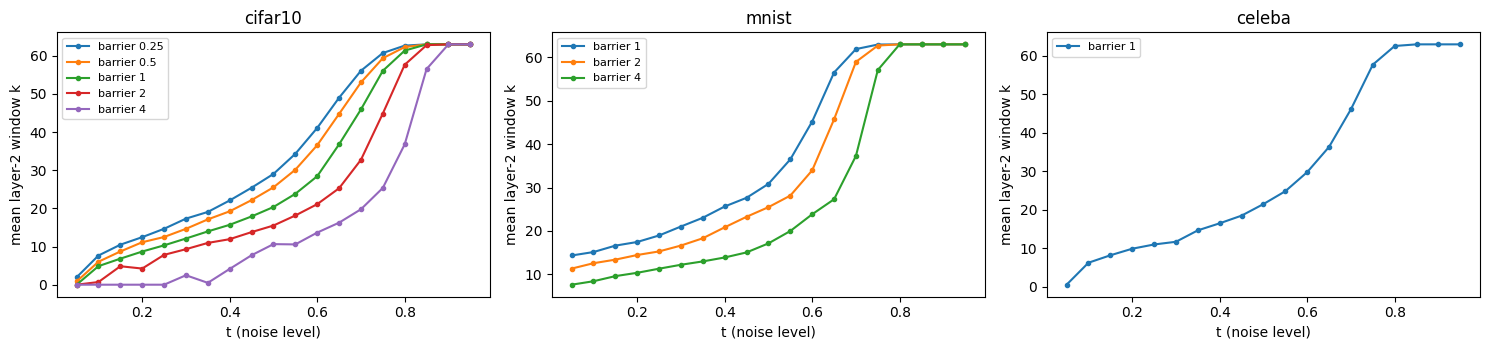

In [5]:
fig, axes = plt.subplots(1, len(DSETS), figsize=(5 * len(DSETS), 3.6), squeeze=False)
for ax, d in zip(axes[0], DSETS):
    for r in sel(dataset=d, method='EBMLS', sort='barrier'):
        kk = r['layer2_k_by_t'] or {}
        if kk:
            ax.plot([float(x) for x in kk], list(kk.values()), marker='.', label=f"barrier {r['barrier']:g}")
    ax.set_xlabel('t (noise level)'); ax.set_ylabel('mean layer-2 window k')
    ax.set_title(d); ax.legend(fontsize=8)
fig.tight_layout()

## Figure 4 — how close the samples get to the training set

/tmp/ipykernel_61316/2024848136.py:7: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  ax.hist(torch.load(p).numpy(), bins=40, histtype='step', label=r['config'])


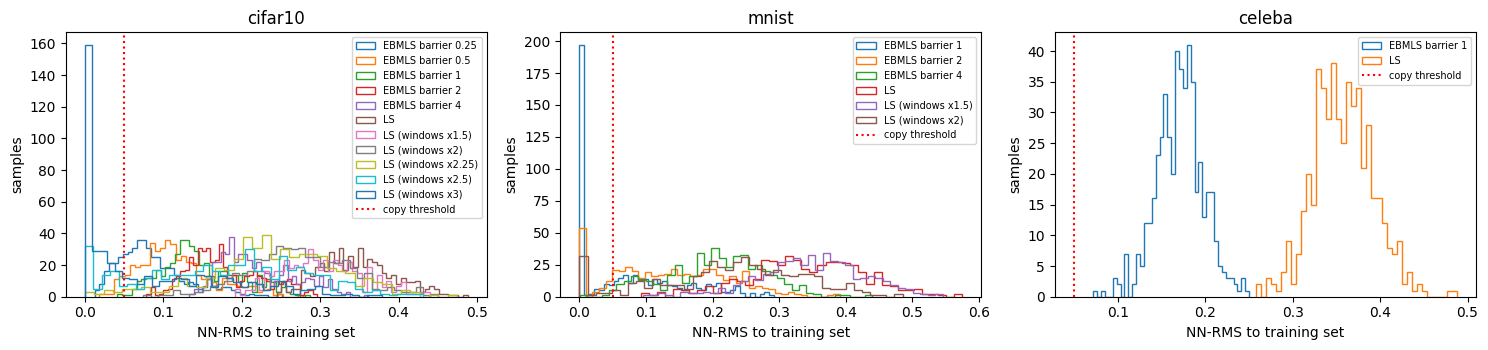

In [6]:
fig, axes = plt.subplots(1, len(DSETS), figsize=(5 * len(DSETS), 3.6), squeeze=False)
for ax, d in zip(axes[0], DSETS):
    for r in sorted([r for r in sel(dataset=d) if r['method'] != 'real'],
                    key=lambda r: (r['method'], r['mult'], r['barrier'] or 0)):
        p = r['dir'] / 'nn_rms.pt'
        if p.exists():
            ax.hist(torch.load(p).numpy(), bins=40, histtype='step', label=r['config'])
    ax.axvline(0.05, c='r', ls=':', label='copy threshold')
    ax.set_xlabel('NN-RMS to training set'); ax.set_ylabel('samples')
    ax.set_title(d); ax.legend(fontsize=7)
fig.tight_layout()

## Figure 5 — samples

/tmp/ipykernel_61316/3439549377.py:10: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  full = torch.load(r['dir'] / 'samples_uint8.pt')


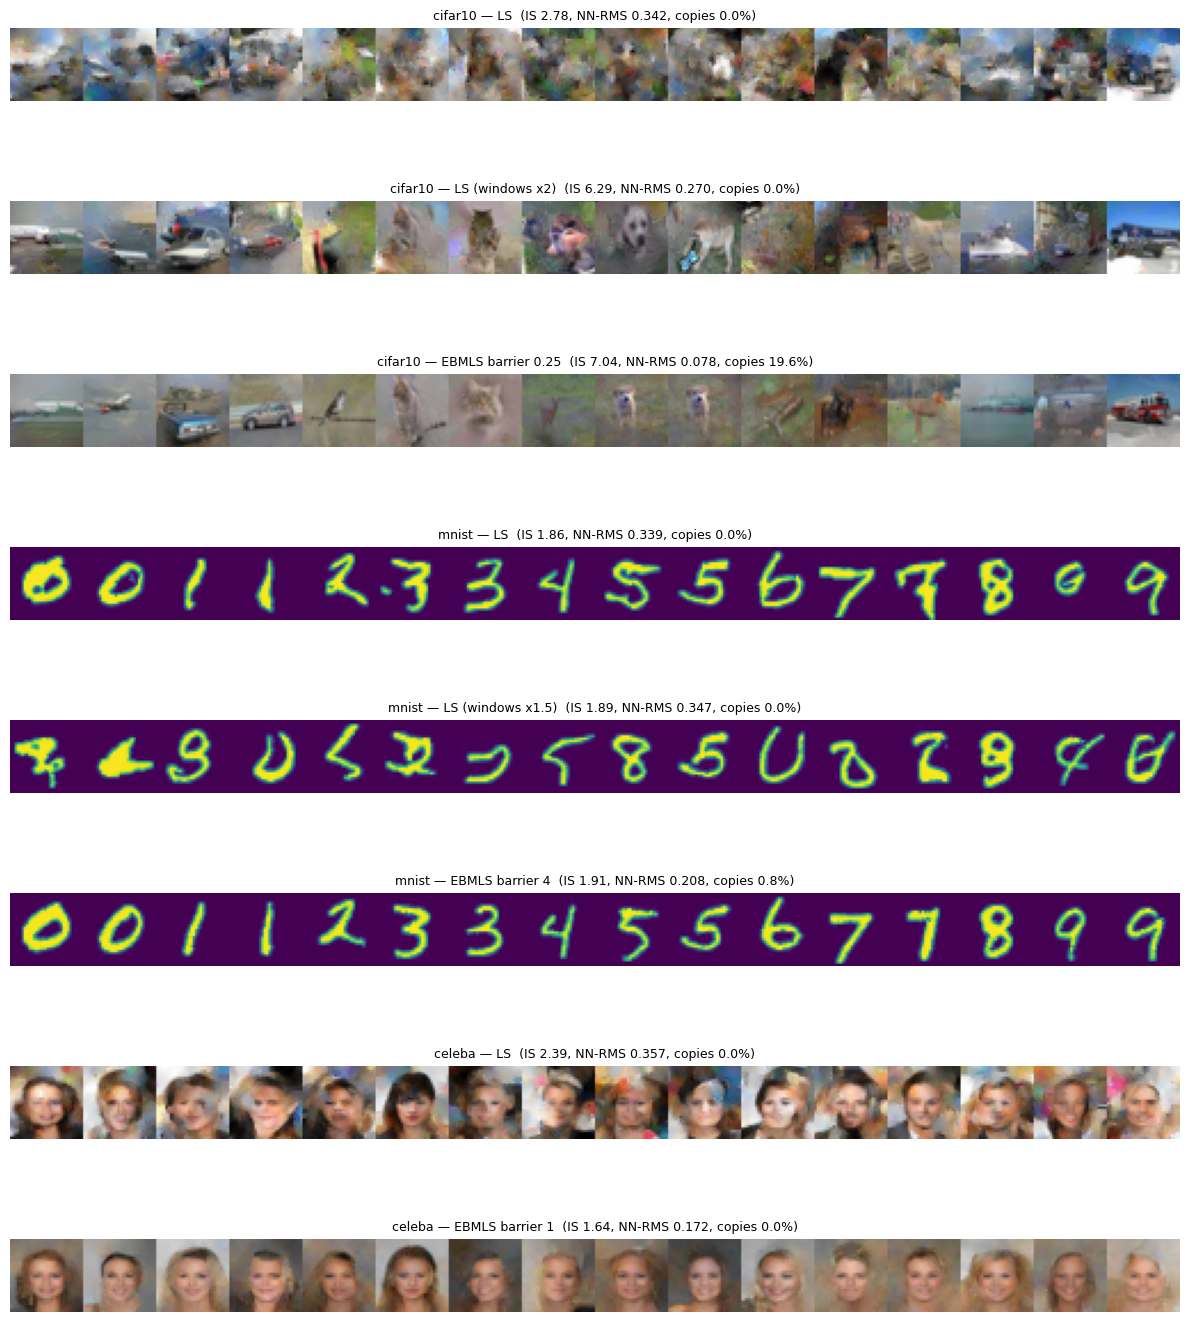

In [7]:
picks = []
for d in DSETS:
    nocopy = [r for r in sel(dataset=d, method='LS') if (r['copy_fraction'] or 0) < 0.01]
    picks += sel(dataset=d, method='LS', mult=1.0)[:1]                                   # baseline
    picks += sorted(nocopy, key=lambda r: -r['IS_mean'])[:1]                             # best non-copying LS
    picks += sorted(sel(dataset=d, method='EBMLS'), key=lambda r: -r['IS_mean'])[:1]     # best EBMLS
picks = [r for i, r in enumerate(picks) if r['dir'] not in [q['dir'] for q in picks[:i]]]
fig, axes = plt.subplots(len(picks), 1, figsize=(12, 1.8 * len(picks)), squeeze=False)
for ax, r in zip(axes[:, 0], picks):
    full = torch.load(r['dir'] / 'samples_uint8.pt')
    u8 = full[torch.linspace(0, len(full) - 1, 16).long()]  # spread over classes, not the first 16
    ax.imshow(np.concatenate(list(u8.permute(0, 2, 3, 1).numpy()), axis=1))
    ax.set_axis_off()
    ax.set_title(f"{r['dataset']} — {r['config']}  (IS {r['IS_mean']:.2f}, "
                 f"NN-RMS {r['nn_rms_median']:.3f}, copies {r['copy_fraction']:.1%})", fontsize=9)
fig.tight_layout()

## Config and provenance

In [8]:
print(json.dumps({
    'model_code_commit': '2c2dc90 (MLS + entropy barrier), harness 2aeebca (scale_multiplier control)',
    'notebook_built_at': subprocess.run(['git', '-C', str(ROOT), 'rev-parse', '--short', 'HEAD'],
                                        capture_output=True, text=True).stdout.strip(),
    'seeds': '0 everywhere; 1 for the two CIFAR-10 repeat runs',
    'nsamples': 500, 'isc_splits': 5, 'genbatch': '50 (20 or 10 for the large-window reruns)',
    'scorebatchsize': '512 (128 or 64 for the large-window reruns)',
    'schedule': 'cosine', 'temperature': 1.0, 'barrier_mode': 'image',
    'cifar10': 'conditional, scales_CIFAR10_ResNet_zeros_conditional.pt, all 50k train images',
    'mnist': 'unconditional, scales_MNIST_ResNet_zeros.pt',
    'celeba': 'unconditional, --max_samples 50000, genbatch 10 / scorebatch 96 (OOM at 50/512)',
    'candidates': 'geomspace(k1+2, 2*image_size-1, 10), odd; image-size independent',
}, indent=1))
seen = set()
for r in RUNS:
    key = (r['dataset'], r['config'])
    if key not in seen and r['method'] != 'real':
        seen.add(key)
        print(f"{r['dataset']:8s} {r['config']:22s} {r['scales']}")

{
 "model_code_commit": "2c2dc90 (MLS + entropy barrier), harness 2aeebca (scale_multiplier control)",
 "notebook_built_at": "",
 "seeds": "0 everywhere; 1 for the two CIFAR-10 repeat runs",
 "nsamples": 500,
 "isc_splits": 5,
 "genbatch": "50 (20 or 10 for the large-window reruns)",
 "scorebatchsize": "512 (128 or 64 for the large-window reruns)",
 "schedule": "cosine",
 "temperature": 1.0,
 "barrier_mode": "image",
 "cifar10": "conditional, scales_CIFAR10_ResNet_zeros_conditional.pt, all 50k train images",
 "mnist": "unconditional, scales_MNIST_ResNet_zeros.pt",
 "celeba": "unconditional, --max_samples 50000, genbatch 10 / scorebatch 96 (OOM at 50/512)",
 "candidates": "geomspace(k1+2, 2*image_size-1, 10), odd; image-size independent"
}
cifar10  LS                     [3, 3, 3, 3, 5, 5, 5, 7, 7, 7, 7, 9, 9, 11, 11, 13, 15, 17, 17, 17]
cifar10  EBMLS barrier 1        [3, 3, 3, 3, 5, 5, 5, 7, 7, 7, 7, 9, 9, 11, 11, 13, 15, 17, 17, 17]
cifar10  EBMLS barrier 2        [3, 3, 3, 3, 5, 5, 

## Reading of the result

**1. The multilayer layer does not pay for itself — it is dominated.** Both families walk the same
trade-off curve toward the real-image score as they drift onto the training set, and at every
matched memorization level plain single-layer LS is the higher of the two:

| at matched copy fraction | EBMLS | LS (wider windows) |
|---|---|---|
| ~0% copies | barrier 1.0 → **IS 3.30** | ×2 → **IS 6.29** |
| ~15–20% copies | barrier 0.25 → **IS 7.04** (19.6%) | ×2.5 → **IS 7.78** (14.6%) |

There is no region of Figure 2 where the second layer wins. This is the answer to the question the
sweep was built to ask, and it is negative.

**2. Why it loses is structural, not a tuning failure.** Layer 2's weights sum to 1 at each pixel,
so $\hat{x}_1 + \delta$ is exactly the layer-2 posterior mean over whole training images — layer 2
*replaces* layer 1's estimate rather than refining it, with layer 1 surviving only through the
weights. Widening its window therefore walks straight to "output a training image", which is why
its memorization rises faster than its IS. Making the second layer genuinely additive (a residual
that cannot represent a single training image on its own) is the change worth trying next.

**3. The Inception Score was in the window width all along.** The scales file is far from
IS-optimal. Uniformly scaling every per-step window by 2 takes CIFAR-10 from **IS 2.78 → 6.29 with
zero samples inside the copy threshold**, reproduced across seeds (2.777/2.857 at ×1, 6.286/6.073
at ×2), so the gain is ~15× the seed spread. Past ×2 it stops being free: ×2.5 copies 15% and ×3
copies 51% while reaching IS 8.40 ≈ the real-image 8.75, which is just memorization and means
nothing. **×2 is the usable operating point.**

**4. The barrier does find a sensible schedule.** Nothing imposes one, yet the selected layer-2
window runs from the full image at high noise down to $k=0$ (layer 2 off) at low noise (Figure 3).
The coarse-to-fine ordering is a real finding even though the layer-2 update rule is not worth its
cost.

**Caveats.** 500 samples with 5 splits understates IS (real CIFAR-10 scores 8.75 here against ~11
in the literature); only relative comparisons on this eval are meaningful. MNIST is uninformative
throughout — real images score 1.915 and every configuration lands within the split spread of it.
CelebA was still generating when this was built; its runs are in the table if present.